# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [20]:
import pandas as pd
import plotly.express as px
import plotly.io as pio
import numpy as np

pio.renderers.default = 'png'          # static images so GitHub renders them
ACCENT, GREY, GREY2 = '#E07B39', '#AAAAAA', '#DDDDDD'
ACCENT_2 = '#2E75B6'
df = pd.read_csv('../data/world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)

(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** The question is a trend over continuous time which suggests a Line chart. Relative scale is more representative of the real situation as compared to absolute one. Grey represent continets which are not as important as the fastest growing and the slowest growing.

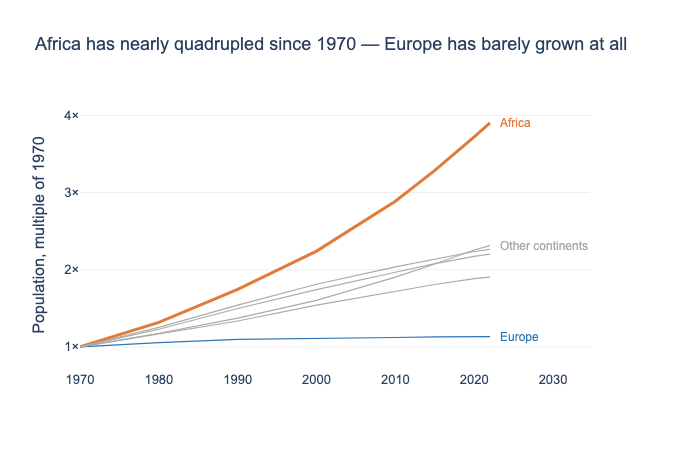

In [23]:
# Q1
g = df_long.groupby(['Continent', 'Year'])['Population'].sum().reset_index()
g['Index'] = g['Population'] / g.groupby('Continent')['Population'].transform('first')

fig = px.line(g, x='Year', y='Index', color='Continent', template='plotly_white', height=450,
              color_discrete_map={c: (ACCENT if c == 'Africa' else ACCENT_2 if c == 'Europe' else GREY) for c in g.Continent.unique()},
              title='Africa has nearly quadrupled since 1970 — Europe has barely grown at all')

fig.update_traces(line_width=1.2, showlegend=False)
fig.update_traces(line_width=3, selector=dict(name='Africa'))
fig.update_xaxes(showgrid=False, title='')
fig.update_yaxes(gridcolor='#EEEEEE', title='Population, multiple of 1970',
                 range=[0.7, 4.2], dtick=1, ticksuffix='×')

last = g[g.Year == 2022].set_index('Continent')['Index']
for c, col in [('Africa', ACCENT), ('Europe', ACCENT_2)]:
    fig.add_annotation(x=2022, y=last[c], text=c, showarrow=False, xanchor='left', xshift=8,
                       font=dict(color=col, size=12))
fig.add_annotation(x=2022, y=last['Oceania'], text='Other continents', showarrow=False,
                   xanchor='left', xshift=8, font=dict(color=GREY, size=12))
fig.update_layout(font=dict(family='Arial', size=13), margin=dict(r=110))
fig.show()

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** ranking suggest me to use horizontal ranked bar chart, African countries in the list are highlighted and clearly visible.

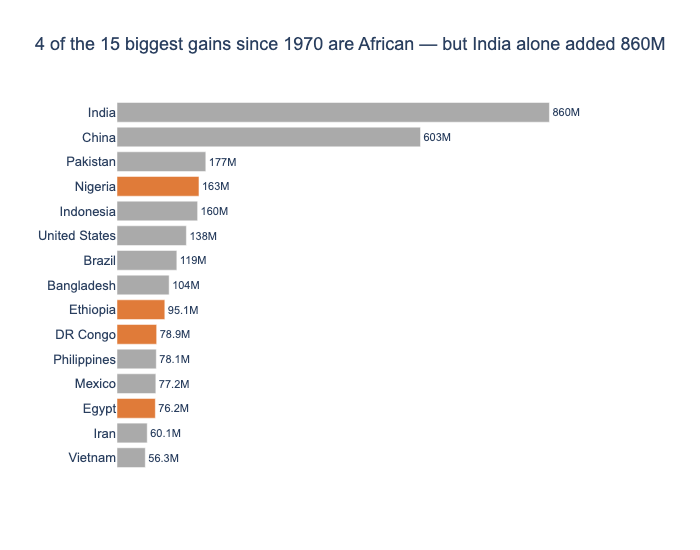

In [24]:
# Q2
d = df.assign(Added=df['2022 Population'] - df['1970 Population']).nlargest(15, 'Added').sort_values('Added')
d['Group'] = np.where(d.Continent == 'Africa', 'Africa', 'Other')

fig = px.bar(d, x='Added', y='Country', orientation='h', color='Group', text_auto='.3s',
             category_orders={'Country': d.Country.tolist()[::-1]},   # value sort, biggest at top
             color_discrete_map={'Africa': ACCENT, 'Other': GREY}, template='plotly_white', height=550,
             title='4 of the 15 biggest gains since 1970 are African — but India alone added 860M')

fig.update_traces(textposition='outside', textfont_size=11)
fig.update_xaxes(range=[0, 1e9], showgrid=False, visible=False)   # zero baseline, labels replace the axis
fig.update_yaxes(title='')
fig.update_layout(showlegend=False, font=dict(family='Arial', size=13))
fig.show()

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** I want to look for probable correlations in two variables, so scatter plot comes to mind, since the population and area in different countries are several magnitudes bigger than in others, log-log scale is used, different continents marked with different colors, different outliers are marked with their name.

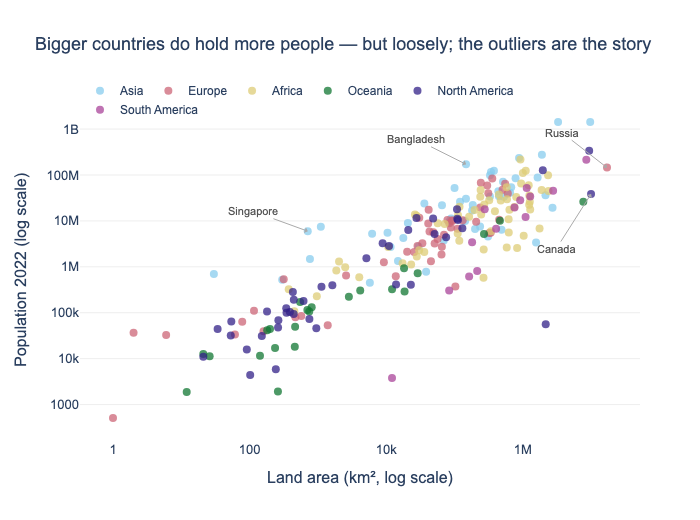

In [25]:
# Q3
fig = px.scatter(df, x='Area', y='2022 Population', color='Continent', hover_name='Country',
                 log_x=True, log_y=True, opacity=0.75, template='plotly_white', height=520,
                 color_discrete_sequence=px.colors.qualitative.Safe,
                 labels={'Area': 'Land area (km², log scale)', '2022 Population': 'Population 2022 (log scale)'},
                 title='Bigger countries do hold more people — but loosely; the outliers are the story')

fig.update_traces(marker_size=8)
fig.update_xaxes(showgrid=False)
fig.update_yaxes(gridcolor='#EEEEEE')

for c, ax, ay in [('Russia', -45, -35), ('Canada', -35, 55), ('Bangladesh', -50, -25), ('Singapore', -55, -20)]:
    r = df.loc[df.Country == c].iloc[0]
    fig.add_annotation(x=np.log10(r.Area), y=np.log10(r['2022 Population']), text=c, ax=ax, ay=ay,
                       arrowhead=1, arrowcolor=GREY, font=dict(size=11, color='#555555'))

fig.update_layout(font=dict(family='Arial', size=13), margin=dict(r=60),
                  legend=dict(orientation='h', y=1.07, x=0, title='', font_size=12))
fig.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** For this type of analysis we need to conduct the 5 number summary for each continent, which is done the best by a box plot, the area is log for the same reasons as before, north america has the biggest internal spread, which is why it is highlighted.

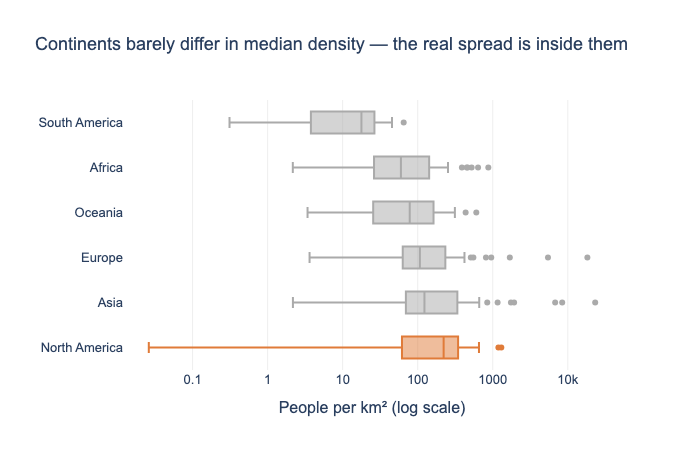

In [13]:
# Q4
order = df.groupby('Continent')['Density'].median().sort_values().index.tolist()

fig = px.box(df, x='Density', y='Continent', color='Continent', points='outliers', log_x=True,
             category_orders={'Continent': order}, template='plotly_white', height=450,
             color_discrete_map={c: (ACCENT if c == 'North America' else GREY) for c in order},
             labels={'Density': 'People per km² (log scale)'},
             title='Continents barely differ in median density — the real spread is inside them')

fig.update_yaxes(title='', showgrid=False)
fig.update_xaxes(gridcolor='#EEEEEE', dtick=1)   # decade ticks only
fig.update_layout(showlegend=False, font=dict(family='Arial', size=13))
fig.show()

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** Those type of questions are best answered by a colored map, since it is pretty and clearly laid out, miler projection for a bigger Europe.

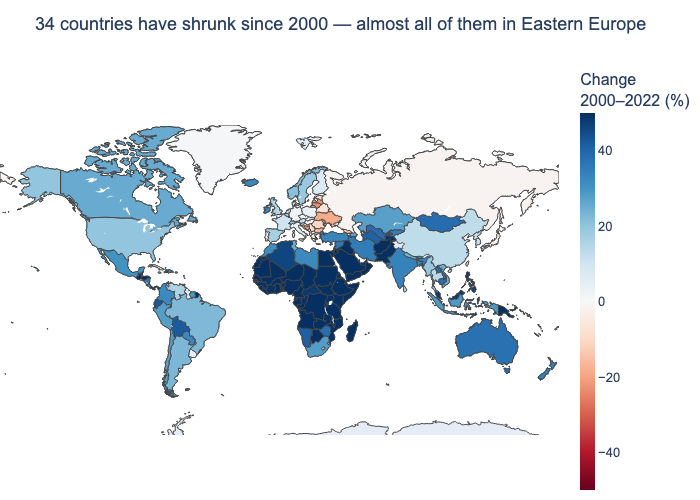

In [28]:
# Q5
d = df.assign(Change=(df['2022 Population'] / df['2000 Population'] - 1) * 100)

fig = px.choropleth(d, locations='CCA3', locationmode='ISO-3', color='Change', hover_name='Country',
                    color_continuous_scale='RdBu', color_continuous_midpoint=0, range_color=[-50, 50],
                    labels={'Change': 'Change 2000–2022 (%)'}, height=500,
                    title='34 countries have shrunk since 2000 — almost all of them in Eastern Europe')

fig.update_geos(projection_type='miller', showframe=False,
                lataxis_range=[-58, 85], showcountries=False)   # drop Antarctica and the empty polar band
fig.update_layout(font=dict(family='Arial', size=13), margin=dict(l=0, r=0, t=60, b=0),
                  coloraxis_colorbar=dict(title='Change<br>2000–2022 (%)', thickness=15))
fig.show()

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** Stacked bar would have been a mess, here, but a Treemap, with a couple of tricks looks informative, for example the graph shows how small the population of Oceania very clearly.

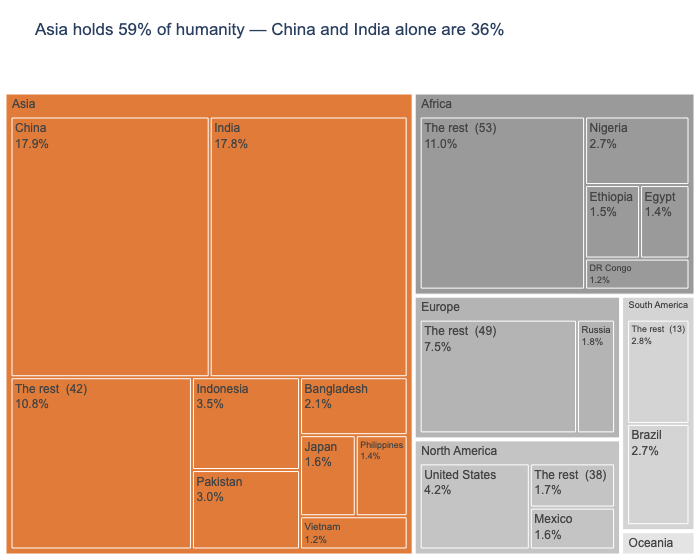

In [32]:
# Q6
greys = ['#9A9A9A', '#B4B4B4', '#C4C4C4', '#D4D4D4', '#E4E4E4']
shade = {c: g for c, g in zip(['Africa', 'Europe', 'North America', 'South America', 'Oceania'], greys)}

r = df.copy()
r['share'] = r['2022 Population'] / r['2022 Population'].sum()
big = r.share >= 0.012                               # a tile only if it is worth labelling
n = r[~big].groupby('Continent').Country.size()
r['Name'] = np.where(big, r.Country, 'The rest ' +  ' (' + r.Continent.map(n).astype(str) + ')')
t = r.groupby(['Continent', 'Name'], as_index=False)['2022 Population'].sum()

fig = px.treemap(t, path=['Continent', 'Name'], values='2022 Population',
                 color='Continent', color_discrete_map={'Asia': ACCENT, **shade}, height=560,
                title='Asia holds 59% of humanity — China and India alone are 36%')

fig.update_traces(texttemplate='%{label}<br>%{percentRoot:.1%}',
                  marker_line_color='white', marker_line_width=1)
fig.update_layout(font=dict(family='Arial', size=12), margin=dict(l=0, r=0, t=70, b=0))
fig.show()

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** 100% stacked bar — the question is about *shares*, so the mix is the story and the total is irrelevant. Africa sits on the zero baseline because it is the segment being compared; the other three are greys, and only Africa is labelled.

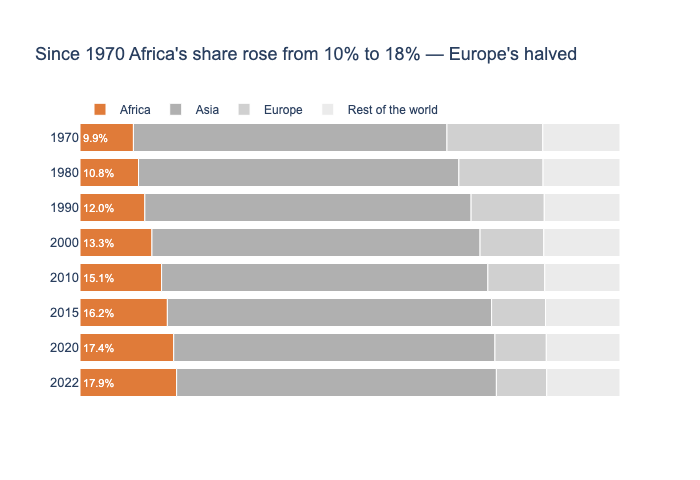

In [33]:
# Q7
g = df_long.copy()
g['Group'] = np.where(g.Continent.isin(['Africa', 'Asia', 'Europe']), g.Continent, 'Rest of the world')
g = g.groupby(['Year', 'Group'])['Population'].sum().reset_index()
g['Share'] = g.Population / g.groupby('Year')['Population'].transform('sum')
g['Label'] = np.where(g.Group == 'Africa', g.Share.map('{:.1%}'.format), '')

fig = px.bar(g, x='Share', y='Year', color='Group', orientation='h', text='Label',
             category_orders={'Group': ['Africa', 'Asia', 'Europe', 'Rest of the world']},
             color_discrete_map={'Africa': ACCENT, 'Asia': '#B0B0B0', 'Europe': '#D0D0D0',
                                 'Rest of the world': '#EBEBEB'},
             template='plotly_white', height=480,
             title='Since 1970 Africa\'s share rose from 10% to 18% — Europe\'s halved')

fig.update_traces(textposition='inside', insidetextanchor='start', textfont=dict(color='white', size=11),
                  marker_line_color='white', marker_line_width=1)
fig.update_xaxes(visible=False, range=[0, 1])
fig.update_yaxes(title='', type='category', autorange='reversed', showgrid=False)
fig.update_layout(font=dict(family='Arial', size=13), margin=dict(t=120),
                  legend=dict(orientation='h', y=1.09, x=0, title='', font_size=12))
fig.show()